# 15｜31101 與兩個同量級站點的借還型態

先選站，再比較曲線。以 2025 年一月觀測到的借出加歸還總量與 31101 的絕對差距排序，取最接近的兩站。同差距時按站點 ID 排序。此處衡量的是事件數，同一旅次的借出與歸還可各貢獻一件事件。

沿用 14 冊口徑。借出與歸還各依自身時間與站點 ID 納入，保留所有車種。沿用檔案日期與小時，時區尚未確認。1/1、1/9、1/20 單列為特殊日，只納入整月選站總量與對帳。平日及週末每小時的平均值除以各自的日曆天數。

In [1]:
import sqlite3
from pathlib import Path
from zipfile import ZipFile

import pandas as pd
from IPython.display import SVG, display

station_id = '31101'
with ZipFile('../data/raw/202501-capitalbikeshare-tripdata.zip') as archive:
    with archive.open('202501-capitalbikeshare-tripdata.csv') as csv:
        rides = pd.read_csv(csv, dtype='string', usecols=[
            'started_at', 'ended_at', 'start_station_id', 'end_station_id',
            'start_station_name', 'end_station_name'])

calendar = pd.DataFrame({'date': pd.date_range('2025-01-01', '2025-01-31')})
calendar['day_type'] = '一般平日'
calendar.loc[calendar.date.dt.dayofweek.ge(5), 'day_type'] = '週末'
calendar.loc[calendar.date.dt.day.isin([1, 9, 20]), 'day_type'] = '特殊日'
days = calendar.groupby('day_type').size().rename('天數')


events = []
for direction, endpoint, time_field in (
    ('借出', 'start', 'started_at'), ('歸還', 'end', 'ended_at')
):
    ids = rides[f'{endpoint}_station_id'].fillna('').str.strip()
    times = pd.to_datetime(rides[time_field], format='mixed', errors='raise')
    keep = ids.ne('') & times.ge('2025-01-01') & times.lt('2025-02-01')
    events.append(pd.DataFrame({'station_id': ids[keep],
                                'name': rides.loc[keep, f'{endpoint}_station_name'],
                                'date': times[keep].dt.normalize(),
                                'hour': times[keep].dt.hour,
                                'direction': direction}))

events = pd.concat(events, ignore_index=True)
monthly = events.groupby('station_id').size().rename('一月借還總量').to_frame()
monthly['與31101的總量差距'] = monthly['一月借還總量'].sub(monthly.at[station_id, '一月借還總量']).abs()
controls = (monthly.drop(index=station_id).reset_index()
            .sort_values(['與31101的總量差距', 'station_id']).head(2))
stations = [station_id, *controls.station_id]
selected = events.loc[events.station_id.isin(stations)].merge(
    calendar, on='date', how='left', validate='many_to_one')
assert selected.day_type.notna().all()
names = (selected.groupby(['station_id', 'name']).size().rename('n').reset_index()
         .sort_values(['station_id', 'n', 'name'], ascending=[True, False, True])
         .drop_duplicates('station_id').set_index('station_id')['name'])
display(monthly.loc[stations].join(names.rename('站名')))

with sqlite3.connect(':memory:') as db:
    selected.drop(columns=['name', 'date']).to_sql('events', db, index=False)
    hourly = pd.read_sql_query('''
        SELECT station_id, day_type, hour, direction, COUNT(*) AS trips
        FROM events
        GROUP BY station_id, day_type, hour, direction
    ''', db)

directions = ['借出', '歸還']
grid = pd.MultiIndex.from_product([stations, days.index, range(24)],
                                  names=['station_id', 'day_type', 'hour'])
counts = (hourly.pivot(index=['station_id', 'day_type', 'hour'], columns='direction', values='trips')
          .reindex(grid).reindex(columns=directions).fillna(0).astype(int))
totals = counts.groupby(level=['station_id', 'day_type']).sum()
direct = pd.crosstab([selected.station_id, selected.day_type], selected.direction)
assert totals.eq(direct.reindex_like(totals).fillna(0)).all().all()
assert totals.sum(axis=1).groupby(level='station_id').sum().eq(monthly.loc[stations, '一月借還總量']).all()
display(totals.join(days, on='day_type'))

daily = counts.div(days, level='day_type', axis=0)
daily['借還差額'] = daily['借出'] - daily['歸還']
comparison = daily.xs(('一般平日', 8), level=('day_type', 'hour')).loc[stations]
assert comparison.loc[station_id].round(2).to_dict() == {'借出': 7.15, '歸還': 2.10, '借還差額': 5.05}
display(comparison.join(names.rename('站名')).round(2))

,一月借還總量,與31101的總量差距,站名
station_id,,,
31101,3803,0,14th & V St NW
31699,3693,110,Eastern Market Metro
31600,3657,146,5th & K St NW


借出    歸還  天數
station_id day_type                
31101      一般平日      1234  1193  20
           特殊日        116   118   3
           週末         557   585   8
31600      一般平日      1244  1240  20
           特殊日        115   112   3
           週末         452   494   8
31699      一般平日      1259  1223  20
           特殊日        141   115   3
           週末         469   486   8

,借出,歸還,借還差額,站名
station_id,,,,
31101,7.15,2.10,5.05,14th & V St NW
31699,3.25,8.00,-4.75,Eastern Market Metro
31600,8.85,2.55,6.30,5th & K St NW


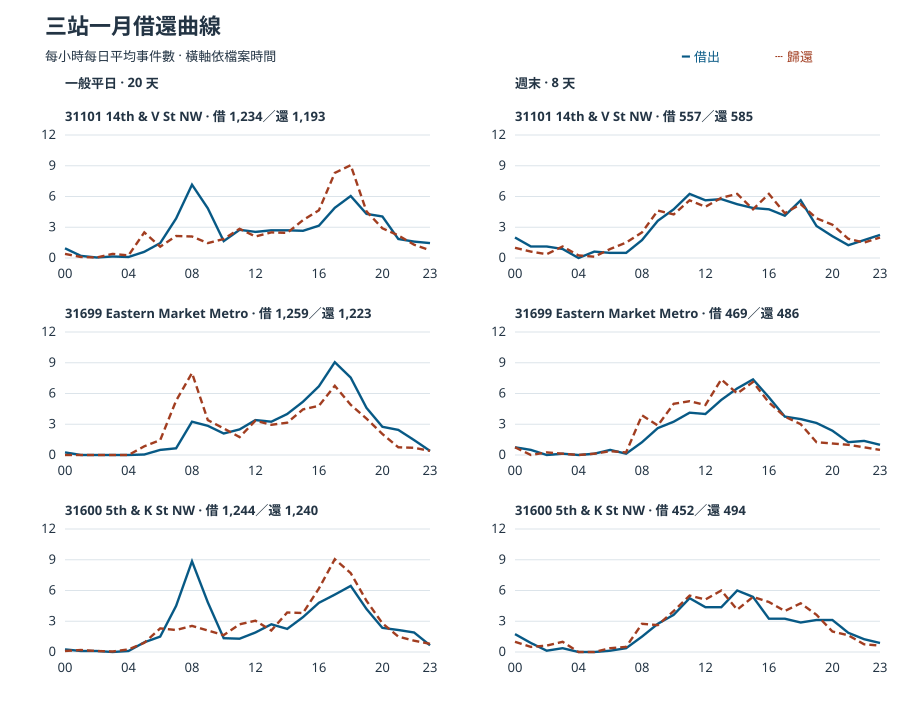

In [2]:
from html import escape
from math import ceil

day_types = ['一般平日', '週末']
max_value = daily.loc[pd.IndexSlice[:, day_types, :], directions].max().max()
step = max(1, ceil(max_value / 4))
y_max = 4 * step

svg = ['<svg xmlns="http://www.w3.org/2000/svg" width="920" height="720" viewBox="0 0 920 720" '
       'role="img" aria-labelledby="title">',
       '<title id="title">三站一月一般平日與週末借還曲線</title>',
       '<rect width="920" height="720" fill="white"/>',
       '<g font-family="sans-serif" fill="#233444" font-size="13">',
       '<text x="45" y="34" font-size="22" font-weight="bold">三站一月借還曲線</text>',
       '<text x="45" y="61">每小時每日平均事件數 · 橫軸依檔案時間</text>',
       '<text x="682" y="61" fill="#075985">━ 借出</text>',
       '<text x="775" y="61" fill="#a13d20">┄ 歸還</text>',
       '<text x="65" y="88" font-weight="bold">一般平日 · 20 天</text>',
       '<text x="515" y="88" font-weight="bold">週末 · 8 天</text>']

height, width = 123, 365
for row, station in enumerate(stations):
    top = 135 + 197 * row
    bottom = top + height
    for day_type, left in zip(day_types, (65, 515)):
        frame = daily.loc[(station, day_type)]
        total = totals.loc[(station, day_type)]
        label = f'{station} {names[station]} · 借 {total["借出"]:,}／還 {total["歸還"]:,}'
        svg.append(f'<text x="{left}" y="{top-14}" font-weight="bold">{escape(label)}</text>')
        for tick in range(0, y_max + 1, step):
            y = bottom - tick * height / y_max
            svg.append(f'<path d="M{left} {y}h{width}" stroke="#dce4ea"/>')
            svg.append(f'<text x="{left-9}" y="{y+4}" text-anchor="end">{tick}</text>')
        for hour in (0, 4, 8, 12, 16, 20, 23):
            x = left + hour * width / 23
            svg.append(f'<text x="{x:.1f}" y="{bottom+20}" text-anchor="middle">{hour:02d}</text>')
        for direction, color, dash in zip(directions, ['#075985', '#a13d20'], ['none', '7 4']):
            points = [(left + hour * width / 23, bottom - value * height / y_max)
                      for hour, value in frame[direction].items()]
            coords = ' '.join(f'{x:.1f},{y:.1f}' for x, y in points)
            svg.append(f'<polyline points="{coords}" fill="none" stroke="{color}" '
                       f'stroke-width="2.4" stroke-dasharray="{dash}"/>')
svg.append('</g></svg>')
figure = Path('../figures/january_station_comparison.svg')
figure.write_text('\n'.join(svg), encoding='utf-8')
display(SVG(filename=str(figure)))

一般平日 08:00–08:59，31101 與 31600 每日分別多借出 5.05、6.30 件，月借還量相近的 31699 則每日多歸還 4.75 件。可先調查這三站的平日 08:00–08:59，核對站點容量、時段庫存及調度紀錄，以了解借還方向差異是否伴隨持續低庫存或接近滿站。三站的比較限於一月有站點 ID 的事件。

## 平日 08:00–08:59 的逐日穩定性

固定三站與 20 個一般平日。未觀測到某方向的事件時，該方向計零。另逐站移除最支持月平均方向的一天，檢查平均差額是否翻轉；同差額時移除較早的日期。

In [3]:
weekdays = calendar.loc[calendar.day_type.eq('一般平日'), 'date']
assert len(weekdays) == 20
morning = selected.loc[selected.hour.eq(8) & selected.day_type.eq('一般平日')]
day_grid = pd.MultiIndex.from_product([stations, weekdays], names=['station_id', 'date'])
morning_counts = (morning.groupby(['station_id', 'date', 'direction']).size()
                  .unstack('direction').reindex(day_grid).reindex(columns=directions)
                  .fillna(0).astype(int))
expected = counts.xs(('一般平日', 8), level=('day_type', 'hour')).loc[stations]
assert morning_counts.groupby(level='station_id').sum().loc[stations].equals(expected)
morning_counts['借還差額'] = morning_counts['借出'] - morning_counts['歸還']

gap = morning_counts['借還差額']
stability = pd.DataFrame({
    '借出較多天數': gap.gt(0).groupby(level='station_id').sum(),
    '歸還較多天數': gap.lt(0).groupby(level='station_id').sum(),
    '相同天數': gap.eq(0).groupby(level='station_id').sum(),
    '差額中位數': gap.groupby(level='station_id').median(),
    '平均差額': gap.groupby(level='station_id').mean(),
}).loc[stations]
assert stability[['借出較多天數', '歸還較多天數', '相同天數']].sum(axis=1).eq(len(weekdays)).all()

for station in stations:
    daily_gap = gap.loc[station]
    strongest = daily_gap.idxmax() if daily_gap.sum() > 0 else daily_gap.idxmin()
    stability.loc[station, '移除日期'] = strongest.strftime('%m/%d')
    stability.loc[station, '該日差額'] = daily_gap.loc[strongest]
    stability.loc[station, '移除後平均差額'] = daily_gap.drop(strongest).mean()

daily_table = morning_counts.unstack('station_id').swaplevel(axis=1)
display(daily_table.reindex(columns=pd.MultiIndex.from_product(
    [stations, [*directions, '借還差額']], names=daily_table.columns.names)))
display(stability.round(2))

station_id 31101         31699          31600        
direction     借出 歸還 借還差額    借出  歸還 借還差額    借出 歸還 借還差額
date                                                 
2025-01-02     9  4    5     1   5   -4     5  2    3
2025-01-03     6  3    3     7   3    4     5  3    2
2025-01-06     0  0    0     0   1   -1     0  0    0
2025-01-07     0  0    0     1   1    0     0  2   -2
2025-01-08     2  0    2     0   4   -4     3  1    2
2025-01-10     4  2    2     1   4   -3     9  3    6
2025-01-13     6  2    4     2   6   -4     9  1    8
2025-01-14    11  1   10     8  11   -3    15  1   14
2025-01-15     9  3    6     0  12  -12    13  2   11
2025-01-16     6  1    5     0  12  -12    11  3    8
2025-01-17     0  1   -1     4   9   -5    10  2    8
2025-01-21     7  2    5     2  13  -11     7  2    5
2025-01-22     5  2    3     6  12   -6     9  2    7
2025-01-23    10  6    4     1   5   -4    10  3    7
2025-01-24     7  3    4     2   4   -2     7  4    3
2025-01-27    11  3    8     8   9   -1    11  2    9
2025-01-28    14  2   12     9  14   -5    16  5   11
2025-01-29    13  1   12     4  13   -9    13  3   10
2025-01-30    15  3   12     4  13   -9    17  9    8
2025-01-31     8  3    5     5   9   -4     7  1    6

,借出較多天數,歸還較多天數,相同天數,差額中位數,平均差額,移除日期,該日差額,移除後平均差額
station_id,,,,,,,,
31101,17,1,2,4.5,5.05,01/28,12.0,4.68
31699,1,18,1,-4.0,-4.75,01/15,-12.0,-4.37
31600,18,1,1,7.0,6.30,01/14,14.0,5.89
